In [27]:
# Probability Cal
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm
import scipy.stats as stats

In [5]:
df = pd.read_csv("diabetes.csv")
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [6]:
x=100
y=140

In [7]:
mean = df["Glucose"].mean()
std = df["Glucose"].std()


In [8]:
#PEople with  between x and y
between = df[(df["Glucose"] >= x) & (df["Glucose"] <= y )]
print(f"Between {x} and {y}")
print("Count=",len(between))
print("Percentage =", len(between) / len(df) * 100)

Between 100 and 140
Count= 379
Percentage = 49.34895833333333


In [13]:
# Normal Distr Prob
p_between = norm.cdf(y,mean,std) - norm.cdf(x,mean,std)
print("Normal probability = " , p_between)

Normal probability =  0.46821958211558595


In [14]:
#people with glucose up to x
up_to_x = df[df["Glucose"] <= x]
print("Up to ", x)
print(f"Count = {len(up_to_x)}")
print(f"Percentage = {len(up_to_x) / len(df) * 100}")

Up to  100
Count = 214
Percentage = 27.864583333333332


In [16]:
#People with glucose above x
above_x = df[df["Glucose"] > x]
print("ABove",x)
print("Count=",len(above_x))
print("Percentage =",len(above_x)/len(df)*100)

ABove 100
Count= 554
Percentage = 72.13541666666666


In [17]:
# 1 - CDF
p_above_x = 1 -norm.cdf(x,mean,std)
print("Normal Probability =", p_above_x)

Normal Probability = 0.7432872912545341


In [ ]:
# Centrallimit theorem

In [23]:
sample_means = []
n_sample = 100
sample_size = 30

In [24]:
for _ in range(n_sample):
    sample = df["Glucose"].sample(n=sample_size,
    replace = True)
    sample_means.append(sample.mean())

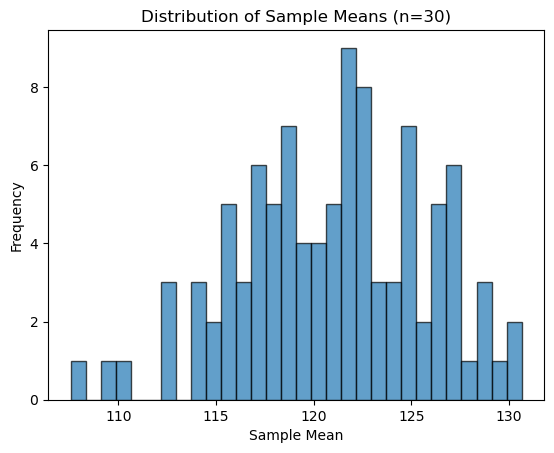

In [25]:
plt.hist(sample_means,bins=30,edgecolor ='k', alpha=0.7)
plt.title("Distribution of Sample Means (n=30)")
plt.xlabel("Sample Mean")
plt.ylabel("Frequency")
plt.show()

In [28]:
# shapiro test
shapiro = stats.shapiro(sample_means)
print(f"Test Statistics (W) : {shapiro.statistic}")
print(f"P-Value : {shapiro.pvalue}")

Test Statistics (W) : 0.9886617709917214
P-Value : 0.5582028327655904


In [32]:
alpha = 0.05
if shapiro.pvalue > alpha:
    print("Data is may be normally distributed")
else:
    print("Data is not normally distributed")

Data is may be normally distributed


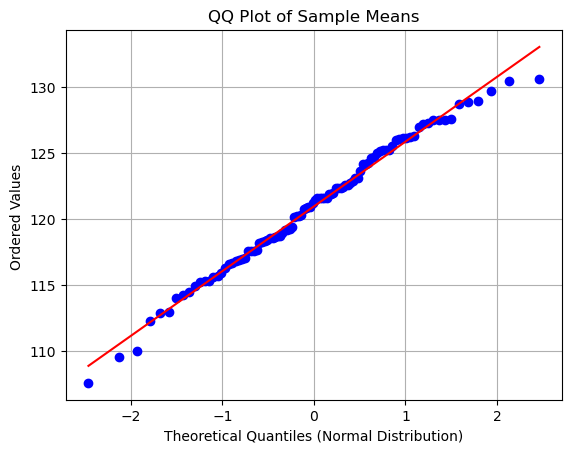

In [31]:
# QQ Plot

stats.probplot(sample_means, dist="norm",plot = plt)
plt.title("QQ Plot of Sample Means")
plt.xlabel("Theoretical Quantiles (Normal Distribution)")
plt.ylabel("Ordered Values ")
plt.grid(True)
plt.show()

In [38]:
df["Age"].unique()

array([50, 31, 32, 21, 33, 30, 26, 29, 53, 54, 34, 57, 59, 51, 27, 41, 43,
       22, 38, 60, 28, 45, 35, 46, 56, 37, 48, 40, 25, 24, 58, 42, 44, 39,
       36, 23, 61, 69, 62, 55, 65, 47, 52, 66, 49, 63, 67, 72, 81, 64, 70,
       68], dtype=int64)